In [4]:
import os
import subprocess

LOCAL_DATA_DIR = "data_deteccion"
os.makedirs(f"{LOCAL_DATA_DIR}/images", exist_ok=True)
os.makedirs(f"{LOCAL_DATA_DIR}/labels", exist_ok=True)

BUCKET = "s3://humanoid-damage-cnn-834257582282-us-east-1-an/processed/damage_classification"

# Sincronizamos imágenes y etiquetas desde S3 a disco local
subprocess.run(["aws", "s3", "sync", f"{BUCKET}/images/", f"{LOCAL_DATA_DIR}/images/", "--quiet"], check=True)
subprocess.run(["aws", "s3", "sync", f"{BUCKET}/labels/", f"{LOCAL_DATA_DIR}/labels/", "--quiet"], check=True)
subprocess.run(["aws", "s3", "cp", f"{BUCKET}/classes.txt", f"{LOCAL_DATA_DIR}/classes.txt", "--quiet"], check=True)
subprocess.run(["aws", "s3", "cp", f"{BUCKET}/data.yaml", f"{LOCAL_DATA_DIR}/data.yaml", "--quiet"], check=True)

n_images = len(os.listdir(f"{LOCAL_DATA_DIR}/images"))
n_labels = len(os.listdir(f"{LOCAL_DATA_DIR}/labels"))
print(f"Imágenes: {n_images} | Labels: {n_labels}")

Imágenes: 6453 | Labels: 6453


In [5]:
from collections import Counter
import glob

# Clases originales tal como están en classes.txt (el índice acá es el que
# usan los .txt de labels crudos).
CLASSES_PATH = f"{LOCAL_DATA_DIR}/classes.txt"
with open(CLASSES_PATH) as f:
    CLASS_NAMES_FULL = [line.strip() for line in f if line.strip()]

# Solo clases con suficientes ejemplos (~300+). Las demás se descartan.
CLASS_NAMES = [
    "Diagonal crack",
    "Concrete spalling",
    "Corrosion",
    "Shear crack",
    "Flexural/rocking crack",
    "Debris",
    "Detachment crack",
]
N_CLASSES = len(CLASS_NAMES)

# Mapeo class_id ORIGINAL -> class_id NUEVO (0..N_CLASSES-1). Las clases
# excluidas no quedan en este diccionario: CLASS_ID_MAP.get(id) devuelve None
# para ellas, y en el resto del notebook eso significa "ignorar esta línea".
CLASS_ID_MAP = {
    CLASS_NAMES_FULL.index(nombre): nuevo_id
    for nuevo_id, nombre in enumerate(CLASS_NAMES)
}

print(f"Clases en classes.txt: {len(CLASS_NAMES_FULL)}")
print(f"Clases que vamos a usar: {N_CLASSES}")
for nuevo_id, nombre in enumerate(CLASS_NAMES):
    print(f"  {nuevo_id}: {nombre}")

# Conteo de ejemplos por clase, ya filtrado. Lo usamos en la próxima celda
# para calcular los pesos de rebalanceo.
conteo = Counter()
for label_path in glob.glob(f"{LOCAL_DATA_DIR}/labels/*.txt"):
    with open(label_path) as f:
        for line in f:
            partes = line.split()
            if len(partes) != 5:
                continue
            class_id = CLASS_ID_MAP.get(int(partes[0]))
            if class_id is None:
                continue  # clase excluida
            conteo[CLASS_NAMES[class_id]] += 1

print("\nConteo de daños por clase")
for clase, cantidad in conteo.most_common():
    print(f"  {clase}: {cantidad}")
print(f"\nTotal de daños anotados usados: {sum(conteo.values())}")

Clases en classes.txt: 14
Clases que vamos a usar: 7
  0: Diagonal crack
  1: Concrete spalling
  2: Corrosion
  3: Shear crack
  4: Flexural/rocking crack
  5: Debris
  6: Detachment crack

Conteo de daños por clase
  Diagonal crack: 4490
  Concrete spalling: 4467
  Corrosion: 2927
  Shear crack: 1283
  Flexural/rocking crack: 504
  Debris: 307
  Detachment crack: 306

Total de daños anotados usados: 14284


In [6]:
# Pesos de rebalanceo por clase: inversamente proporcional a la frecuencia,
# normalizado para que la clase más común tenga peso 1. Las clases raras
# pesan más en la loss (detection_loss, más abajo) y se sobremuestrean más
# en el split de train (repeticiones_por_rareza, más abajo).
max_conteo = max(conteo[c] for c in CLASS_NAMES)
CLASS_WEIGHTS = [max_conteo / conteo[c] for c in CLASS_NAMES]

print("Pesos por clase:")
for nombre, peso in zip(CLASS_NAMES, CLASS_WEIGHTS):
    print(f"  {nombre}: {peso:.2f}")

Pesos por clase:
  Diagonal crack: 1.00
  Concrete spalling: 1.01
  Corrosion: 1.53
  Shear crack: 3.50
  Flexural/rocking crack: 8.91
  Debris: 14.63
  Detachment crack: 14.67


In [7]:
import numpy as np

# Ya no usamos una grilla: cada imagen predice un número FIJO de "slots" de
# caja (MAX_BOXES). Necesitamos que MAX_BOXES sea >= al máximo de daños reales
# que puede tener una sola imagen, si no perdemos anotaciones.
max_danos_en_imagen = 0
for label_path in glob.glob(f"{LOCAL_DATA_DIR}/labels/*.txt"):
    with open(label_path) as f:
        n = sum(1 for line in f if len(line.split()) == 5 and CLASS_ID_MAP.get(int(line.split()[0])) is not None)
    max_danos_en_imagen = max(max_danos_en_imagen, n)

MAX_BOXES = max_danos_en_imagen + 5  # margen extra sobre el máximo observado
print(f"Máximo de daños anotados en una sola imagen: {max_danos_en_imagen}")
print(f"MAX_BOXES elegido: {MAX_BOXES}")

Máximo de daños anotados en una sola imagen: 26
MAX_BOXES elegido: 31


In [8]:
def parse_label_to_boxes(label_path, max_boxes=MAX_BOXES, n_classes=N_CLASSES):
    """Convierte un archivo de labels (formato YOLO) en un target de tamaño
    FIJO (max_boxes, 1+4+n_classes): cada fila es un daño real (objectness=1,
    con su caja y clase) o padding (objectness=0, resto en cero). A diferencia
    de la grilla, acá xc/yc/w/h quedan en coordenadas absolutas de la imagen
    completa (0-1), no relativas a ninguna celda: no hay celdas."""
    target = np.zeros((max_boxes, 1 + 4 + n_classes), dtype=np.float32)
    if not os.path.exists(label_path):
        return target  # imagen sin ningún daño anotado

    entries = []
    with open(label_path) as f:
        for line in f:
            partes = line.split()
            if len(partes) != 5:
                continue
            class_id = CLASS_ID_MAP.get(int(partes[0]))
            if class_id is None:
                continue  # clase excluida
            xc, yc, w, h = map(float, partes[1:5])
            entries.append((xc, yc, w, h, class_id))

    entries = entries[:max_boxes]  # si hay más daños que max_boxes, se descartan los sobrantes
    for i, (xc, yc, w, h, class_id) in enumerate(entries):
        target[i, 0] = 1.0
        target[i, 1:5] = [xc, yc, w, h]
        target[i, 5 + int(class_id)] = 1.0
    return target

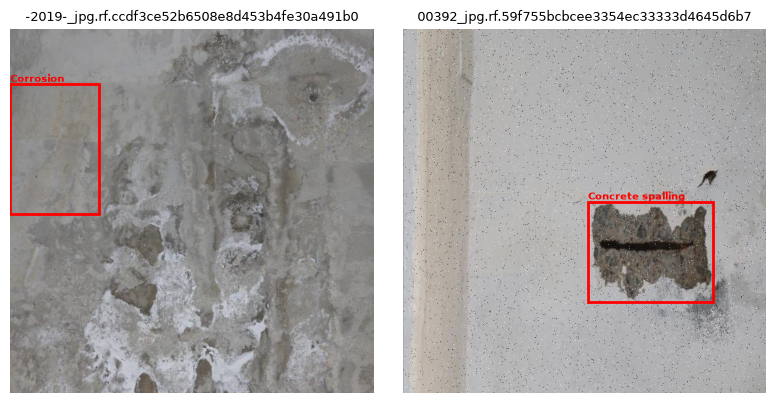

In [9]:
#PARA PROBAR
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

def plot_real_box_on_image(label_path, ax):
    """Dibuja las cajas reales anotadas, directo en coordenadas absolutas de
    la imagen (sin celdas de por medio)."""
    boxes = parse_label_to_boxes(label_path)
    valid = boxes[:, 0] == 1

    img_name = os.path.basename(label_path).replace(".txt", "")
    img_path = None
    for ext in [".jpg", ".jpeg", ".png"]:
        candidate = f"{LOCAL_DATA_DIR}/images/{img_name}{ext}"
        if os.path.exists(candidate):
            img_path = candidate
            break

    img = Image.open(img_path)
    img_w, img_h = img.size
    ax.imshow(img)

    for xc, yc, w, h, *class_onehot in boxes[valid, 1:]:
        box_w = w * img_w
        box_h = h * img_h
        x0 = xc * img_w - box_w / 2
        y0 = yc * img_h - box_h / 2

        rect = patches.Rectangle((x0, y0), box_w, box_h,
                                  linewidth=2, edgecolor="red",
                                  facecolor="none")
        ax.add_patch(rect)
        class_idx = int(np.argmax(class_onehot))
        ax.text(x0, y0 - 4, CLASS_NAMES[class_idx],
                color="red", fontsize=7, weight="bold")

    ax.set_title(img_name, fontsize=9)
    ax.axis("off")


# Elegimos 2 labels random que tengan al menos un daño anotado
labels_con_dano = []
for label_path in glob.glob(f"{LOCAL_DATA_DIR}/labels/*.txt"):
    boxes = parse_label_to_boxes(label_path)
    if boxes[:, 0].sum() > 0:
        labels_con_dano.append(label_path)

muestras = random.sample(labels_con_dano, 2)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, label_path in zip(axes, muestras):
    plot_real_box_on_image(label_path, ax)

plt.tight_layout()
plt.show()

In [10]:
image_files = sorted(glob.glob(f"{LOCAL_DATA_DIR}/images/*.jpg"))

def get_label_path(image_path):
    image_path = image_path.replace("\\", "/")  # normaliza separadores (Windows usa \)
    return image_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"

MAX_REPEATS = 6  # tope de repeticiones por imagen: evita que una imagen con una
                  # clase muy rara infle demasiado el dataset de entrenamiento

def repeticiones_por_rareza(label_path):
    """Cuántas veces repetir esta imagen en train, según la clase más rara que contenga."""
    if not os.path.exists(label_path):
        return 1
    max_peso = 1.0
    with open(label_path) as f:
        for line in f:
            partes = line.split()
            if len(partes) != 5:
                continue
            class_id = CLASS_ID_MAP.get(int(partes[0]))
            if class_id is None:
                continue  # clase excluida, no influye en el sobremuestreo
            max_peso = max(max_peso, CLASS_WEIGHTS[class_id])
    return min(MAX_REPEATS, max(1, round(max_peso)))

# Split 80/20 sobre las imágenes ORIGINALES, antes del sobremuestreo. Así
# evitamos que copias de la misma imagen terminen repartidas entre train y validation.
RANDOM_SEED = 42
TRAIN_RATIO = 0.8
random.seed(RANDOM_SEED)
image_files_shuffled = list(image_files)
random.shuffle(image_files_shuffled)
n_train_original = int(len(image_files_shuffled) * TRAIN_RATIO)
train_original_paths = image_files_shuffled[:n_train_original]
val_paths = image_files_shuffled[n_train_original:]

# El sobremuestreo solo se aplica a train, nunca a validation.
train_paths = []
for img_path in train_original_paths:
    n_rep = repeticiones_por_rareza(get_label_path(img_path))
    train_paths.extend([img_path] * n_rep)

overlap = set(train_paths) & set(val_paths)
assert len(overlap) == 0, f"DATA LEAKAGE: {len(overlap)} imágenes aparecen en train y validation"

print(f"Imágenes originales: {len(image_files)}")
print(f"Train original: {len(train_original_paths)} | Train tras sobremuestreo: {len(train_paths)}")
print(f"Validation sin sobremuestreo: {len(val_paths)}")

Imágenes originales: 6453
Train original: 5162 | Train tras sobremuestreo: 9730
Validation sin sobremuestreo: 1291


In [11]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 50
LEARNING_RATE = 1e-4
CHECKPOINT_PATH = "../models/best_detector_2.keras"
RUN_TRAINING = False
os.makedirs(os.path.dirname(CHECKPOINT_PATH), exist_ok=True)

def load_sample(image_path):
    image_path = image_path.numpy().decode("utf-8")
    image_path_norm = image_path.replace("\\", "/")  # normaliza separadores
    label_path = image_path_norm.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    img = tf.keras.utils.load_img(image_path, target_size=IMG_SIZE)
    img_array = tf.keras.utils.img_to_array(img) / 255.0
    target = parse_label_to_boxes(label_path)
    return img_array, target

def tf_load_sample(image_path):
    img, target = tf.py_function(load_sample, [image_path], [tf.float32, tf.float32])
    img.set_shape([224, 224, 3])
    target.set_shape([MAX_BOXES, 1 + 4 + N_CLASSES])
    return img, target

train_ds = tf.data.Dataset.from_tensor_slices(train_paths).shuffle(
    buffer_size=len(train_paths), seed=RANDOM_SEED, reshuffle_each_iteration=True
).map(
    tf_load_sample, num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = tf.data.Dataset.from_tensor_slices(val_paths).map(
    tf_load_sample, num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Datasets armados")

Datasets armados


In [12]:
sample_images, sample_targets = next(iter(train_ds))
frac_positivas = (sample_targets[..., 0] == 1).numpy().mean()
print(f"Fracción de slots con daño real en un batch: {frac_positivas:.4f}")
print(f"O sea, aprox {frac_positivas * MAX_BOXES:.1f} slots positivos de {MAX_BOXES} totales, por imagen")

# Chequeo de imágenes: si esto NO muestra valores entre 0 y 1, algo quedó mal normalizado
print(f"Rango de píxeles de la imagen: min={sample_images.numpy().min():.3f}, max={sample_images.numpy().max():.3f}")

Fracción de slots con daño real en un batch: 0.0585
O sea, aprox 1.8 slots positivos de 31 totales, por imagen
Rango de píxeles de la imagen: min=0.000, max=1.000


In [13]:
# Reutilizamos el modelo 1 (el clasificador daño / no-daño ya entrenado) como
# EXTRACTOR DE FEATURES para este modelo nuevo, en vez de entrenar una red
# desde cero con menos datos. El modelo 1 tiene, a grandes rasgos, esta forma:
#   Input -> [Conv2D + MaxPooling2D] x N -> GlobalAveragePooling -> Dense -> salida binaria
# Nos interesa todo lo anterior a GlobalAveragePooling: esas capas ya
# aprendieron a "leer" texturas de daño en la imagen. La salida binaria
# (daño / no-daño) no la usamos acá, la descartamos.
modelo1 = tf.keras.models.load_model("../models/best_model.keras")

# Recorremos las capas del modelo 1 y nos quedamos con la salida de la
# ÚLTIMA MaxPooling2D: el punto justo antes de que empiece la parte de
# clasificación (GlobalAveragePooling + Dense).
backbone_output = None
for layer in modelo1.layers:
    if isinstance(layer, tf.keras.layers.MaxPooling2D):
        backbone_output = layer.output
assert backbone_output is not None, "No se encontró ninguna capa MaxPooling2D en modelo1"

# Armamos un modelo nuevo que es "el modelo 1 cortado ahí": recibe una imagen
# y devuelve un mapa de features 14x14 (no una predicción, sino la imagen
# "interpretada" en el lenguaje interno de la red). Este mapa se sigue usando
# como features intermedias, aunque ya no exista una grilla de predicción.
backbone = tf.keras.Model(inputs=modelo1.input, outputs=backbone_output, name="backbone_reutilizado")

# Arranca CONGELADO: en la Fase 1 del entrenamiento (más abajo) solo se
# entrena la cabeza nueva, para no arruinar de entrada estos pesos ya
# entrenados con gradientes grandes de una cabeza que todavía es random.
backbone.trainable = False

print("Backbone reutilizado, forma de salida:", backbone.output_shape)

Backbone reutilizado, forma de salida: (None, 14, 14, 256)


In [14]:
from tensorflow.keras import layers

# Cabeza de detección nueva, encima del backbone del modelo 1. A diferencia de
# la versión con grilla, acá NO hay una predicción por celda: el mapa de
# features se colapsa con GlobalAveragePooling2D en un solo vector por imagen,
# y de ahí salen MAX_BOXES "slots" de predicción (objectness, caja, clase),
# cada uno pudiendo representar cualquier daño en cualquier posición.
x = backbone.output  # (14, 14, 256)
x = layers.Conv2D(256, 3, padding="same", activation="relu", name="det_conv2d_1")(x)
x = layers.GlobalAveragePooling2D(name="det_gap")(x)
x = layers.Dense(512, activation="relu", name="det_dense")(x)

# Objectness por slot (MAX_BOXES logits crudos): la loss aplica sigmoid.
# El bias se inicializa con frac_positivas (celda anterior), calculado sobre
# los datos reales ya filtrados.
frac_positivas_segura = np.clip(frac_positivas, 1e-3, 1 - 1e-3)
bias_inicial_objectness = np.log(frac_positivas_segura / (1 - frac_positivas_segura))
print(f"frac_positivas: {frac_positivas:.6f} -> bias_inicial_objectness: {bias_inicial_objectness:.4f}")
out_obj = layers.Dense(
    MAX_BOXES, activation="linear", name="det_obj",
    bias_initializer=tf.keras.initializers.Constant(bias_inicial_objectness),
)(x)
out_obj = layers.Reshape((MAX_BOXES, 1))(out_obj)

# Caja por slot (xc, yc, w, h): TODO absoluto normalizado 0-1 respecto a la
# imagen completa, acotado con sigmoid. No hay celdas, así que no hay offset
# relativo: el centro ya es la posición real en la imagen.
out_box = layers.Dense(MAX_BOXES * 4, activation="sigmoid", name="det_box")(x)
out_box = layers.Reshape((MAX_BOXES, 4))(out_box)

# Clase por slot: logits, se les aplica softmax en la loss.
out_class = layers.Dense(MAX_BOXES * N_CLASSES, activation="linear", name="det_class")(x)
out_class = layers.Reshape((MAX_BOXES, N_CLASSES))(out_class)

output = layers.Concatenate(axis=-1, name="det_output")([out_obj, out_box, out_class])
modelo_deteccion = tf.keras.Model(inputs=backbone.input, outputs=output, name="modelo_deteccion")
modelo_deteccion.summary()

frac_positivas: 0.058468 -> bias_inicial_objectness: -2.7790


Model: "modelo_deteccion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 224, 224,  │          0 │ rescaling[0][0]   │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │        896 │ sequential[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 224, 224,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 112, 112,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 56, 56,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 28, 28,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 28, 28,    │    295,168 │ max_pooling2d_2[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │      1,024 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 14, 14,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ det_conv2d_1        │ (None, 14, 14,    │    590,080 │ max_pooling2d_3[… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ det_gap             │ (None, 256)       │          0 │ det_conv2d_1[0][

 Total params: 1,302,836 (4.97 MB)

 Trainable params: 912,500 (3.48 MB)

 Non-trainable params: 390,336 (1.49 MB)

In [15]:
from scipy.optimize import linear_sum_assignment

# Como ya no hay celdas, no sabemos de antemano qué slot de predicción
# "le corresponde" a cada daño real: dos daños distintos pueden salir en
# cualquier slot. El matching Húngaro resuelve esto en cada batch: busca la
# asignación slot-predicho <-> daño-real que minimiza el error total (caja +
# clase), y solo esa asignación se usa para calcular la loss de caja y clase.
# Es el mismo approach que usa DETR.
CLASS_WEIGHTS_TF = tf.constant(CLASS_WEIGHTS, dtype=tf.float32)

def hungarian_match_batch(true_mask, true_boxes, true_classes, pred_boxes, pred_class_probs):
    """Para cada imagen del batch, asigna cada daño real al slot predicho más
    parecido (menor distancia de caja + mayor probabilidad de la clase
    correcta). Devuelve, por slot, el índice del daño real que le tocó
    (-1 si no le tocó ninguno)."""
    batch = true_mask.shape[0]
    match_idx = np.full((batch, true_boxes.shape[1]), -1, dtype=np.int32)
    for b in range(batch):
        valid = true_mask[b] > 0.5
        n_true = int(valid.sum())
        if n_true == 0:
            continue
        tb = true_boxes[b, valid]
        tc = true_classes[b, valid]
        pb = pred_boxes[b]
        pc = pred_class_probs[b]
        cost_box = np.abs(pb[:, None, :] - tb[None, :, :]).sum(axis=-1)
        true_class_idx = tc.argmax(axis=-1)
        cost_class = 1 - pc[:, true_class_idx]
        cost = cost_box + cost_class
        pred_idx, true_idx = linear_sum_assignment(cost)
        real_idx = np.where(valid)[0]
        for p_i, t_i in zip(pred_idx, true_idx):
            match_idx[b, p_i] = real_idx[t_i]
    return match_idx

def detection_loss(y_true, y_pred, lambda_coord=5.0):
    obj_logits = y_pred[..., 0]
    box_pred = y_pred[..., 1:5]
    class_probs = tf.nn.softmax(y_pred[..., 5:], axis=-1)

    match_idx = tf.numpy_function(
        hungarian_match_batch,
        [y_true[..., 0], y_true[..., 1:5], y_true[..., 5:], box_pred, class_probs],
        tf.int32,
    )
    match_idx.set_shape([None, MAX_BOXES])

    # objectness: el slot "debería" predecir 1 si el matching le asignó un
    # daño real, 0 si quedó sin asignar (padding, o sobra de slots)
    obj_target = tf.cast(match_idx >= 0, tf.float32)
    loss_obj = tf.nn.sigmoid_cross_entropy_with_logits(labels=obj_target, logits=obj_logits)

    # caja y clase: SOLO se penalizan en los slots que sí fueron asignados a
    # un daño real (obj_target), igual que antes con obj_mask en la versión con grilla
    safe_idx = tf.maximum(match_idx, 0)
    matched_box = tf.gather(y_true[..., 1:5], safe_idx, batch_dims=1)
    matched_class = tf.gather(y_true[..., 5:], safe_idx, batch_dims=1)

    loss_box = tf.reduce_sum(tf.square(matched_box - box_pred), axis=-1)
    loss_class = tf.keras.losses.categorical_crossentropy(matched_class, class_probs)
    peso_clase = tf.reduce_sum(matched_class * CLASS_WEIGHTS_TF, axis=-1)

    loss_box = obj_target * loss_box
    loss_class = obj_target * peso_clase * loss_class

    # lambda_coord=5 le da más peso relativo a acertar la caja que a acertar
    # la clase o el objectness (sin esto, la loss de posición queda opacada).
    return tf.reduce_mean(loss_obj) + lambda_coord * tf.reduce_mean(loss_box) + tf.reduce_mean(loss_class)

def obj_accuracy(y_true, y_pred):
    """Qué % de los slots acierta si hay daño o no (objectness)."""
    obj_logits = y_pred[..., 0]
    box_pred = y_pred[..., 1:5]
    class_probs = tf.nn.softmax(y_pred[..., 5:], axis=-1)

    match_idx = tf.numpy_function(
        hungarian_match_batch,
        [y_true[..., 0], y_true[..., 1:5], y_true[..., 5:], box_pred, class_probs],
        tf.int32,
    )
    match_idx.set_shape([None, MAX_BOXES])
    obj_target = tf.cast(match_idx >= 0, tf.float32)
    obj_pred_bin = tf.cast(tf.sigmoid(obj_logits) > 0.5, tf.float32)
    return tf.reduce_mean(tf.cast(tf.equal(obj_pred_bin, obj_target), tf.float32))


def class_accuracy(y_true, y_pred):
    """De los slots CON daño real emparejado, qué % acierta la clase."""
    box_pred = y_pred[..., 1:5]
    class_probs = tf.nn.softmax(y_pred[..., 5:], axis=-1)

    match_idx = tf.numpy_function(
        hungarian_match_batch,
        [y_true[..., 0], y_true[..., 1:5], y_true[..., 5:], box_pred, class_probs],
        tf.int32,
    )
    match_idx.set_shape([None, MAX_BOXES])
    obj_target = tf.cast(match_idx >= 0, tf.float32)

    safe_idx = tf.maximum(match_idx, 0)
    matched_class = tf.gather(y_true[..., 5:], safe_idx, batch_dims=1)

    pred_class_idx = tf.argmax(class_probs, axis=-1)
    true_class_idx = tf.argmax(matched_class, axis=-1)
    aciertos = tf.cast(tf.equal(pred_class_idx, true_class_idx), tf.float32)

    # Promedio SOLO sobre los slots con daño real (obj_target=1), ignorando padding
    return tf.reduce_sum(aciertos * obj_target) / (tf.reduce_sum(obj_target) + 1e-7)

modelo_deteccion.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=1.0),
    loss=detection_loss,
    metrics=[obj_accuracy, class_accuracy],
)

In [16]:
# Fase 1: backbone congelado, solo entrena la cabeza nueva.
if RUN_TRAINING:
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(CHECKPOINT_PATH, save_best_only=True, monitor="val_loss"),
        tf.keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True, monitor="val_loss"),
    ]
    history = modelo_deteccion.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
    )
else:
    print("RUN_TRAINING=False: modelo armado y compilado, entrenamiento no ejecutado")

RUN_TRAINING=False: modelo armado y compilado, entrenamiento no ejecutado


In [17]:
backbone.trainable = True
modelo_deteccion.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE / 10, clipnorm=1.0),
    loss=detection_loss,
    metrics=[obj_accuracy, class_accuracy],
)
print("Backbone descongelado, listo para Fase 2 con LR más bajo")

Backbone descongelado, listo para Fase 2 con LR más bajo


In [18]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4),
    # Guarda el MEJOR modelo visto hasta ahora
    tf.keras.callbacks.ModelCheckpoint(CHECKPOINT_PATH, monitor="val_loss", save_best_only=True),
    # Guarda el estado de CADA época (aunque no sea la mejor), para poder
    # retomar si se corta la conexión a la mitad de la noche
    tf.keras.callbacks.ModelCheckpoint(
        CHECKPOINT_PATH.replace(".keras", "_ultima_epoca.keras"),
        save_best_only=False,
    ),
]

history = modelo_deteccion.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
)

Epoch 1/50


c:\Users\chris\OneDrive\Documentos\GitHub\humanoid-damage-cnn\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


609/609 ━━━━━━━━━━━━━━━━━━━━ 557s 898ms/step - class_accuracy: 0.4646 - loss: 0.7109 - obj_accuracy: 0.9195 - val_class_accuracy: 0.4433 - val_loss: 0.4776 - val_obj_accuracy: 0.9283 - learning_rate: 1.0000e-05
Epoch 2/50
609/609 ━━━━━━━━━━━━━━━━━━━━ 541s 888ms/step - class_accuracy: 0.6399 - loss: 0.4904 - obj_accuracy: 0.9196 - val_class_accuracy: 0.5912 - val_loss: 0.4185 - val_obj_accuracy: 0.9276 - learning_rate: 1.0000e-05
Epoch 3/50
609/609 ━━━━━━━━━━━━━━━━━━━━ 545s 894ms/step - class_accuracy: 0.7314 - loss: 0.4395 - obj_accuracy: 0.9198 - val_class_accuracy: 0.7074 - val_loss: 0.3942 - val_obj_accuracy: 0.9278 - learning_rate: 1.0000e-05
Epoch 4/50
609/609 ━━━━━━━━━━━━━━━━━━━━ 545s 894ms/step - class_accuracy: 0.8047 - loss: 0.4068 - obj_accuracy: 0.9198 - val_class_accuracy: 0.7770 - val_loss: 0.3780 - val_obj_accuracy: 0.9248 - learning_rate: 1.0000e-05
Epoch 5/50
609/609 ━━━━━━━━━━━━━━━━━━━━ 544s 893ms/step - class_accuracy: 0.8478 - loss: 0.3866 - obj_accuracy: 0.9198 - va

In [25]:
for img_path in image_files[:5]:
    label_path = get_label_path(img_path)
    print(img_path, "->", label_path, "| existe:", os.path.exists(label_path))

data_deteccion/images\-1007-_jpg.rf.32bdf2e3378f30059e12a0feba1126d8.jpg -> data_deteccion/labels/-1007-_jpg.rf.32bdf2e3378f30059e12a0feba1126d8.txt | existe: True
data_deteccion/images\-101-_jpg.rf.eeb87e8d17886eb6230f0e3d23fd4a75.jpg -> data_deteccion/labels/-101-_jpg.rf.eeb87e8d17886eb6230f0e3d23fd4a75.txt | existe: True
data_deteccion/images\-1014-_jpg.rf.28cbfa7528f0e61c8fc071bd56e1c5fa.jpg -> data_deteccion/labels/-1014-_jpg.rf.28cbfa7528f0e61c8fc071bd56e1c5fa.txt | existe: True
data_deteccion/images\-1015-_jpg.rf.a29fa3a7d4409164fa3703ca83b03936.jpg -> data_deteccion/labels/-1015-_jpg.rf.a29fa3a7d4409164fa3703ca83b03936.txt | existe: True
data_deteccion/images\-1016-_jpg.rf.1b88d4ff3663533f2a2fd0863fd09fde.jpg -> data_deteccion/labels/-1016-_jpg.rf.1b88d4ff3663533f2a2fd0863fd09fde.txt | existe: True


In [22]:
import inspect
print(inspect.getsource(get_label_path))

def get_label_path(image_path):
    image_path = image_path.replace("\\", "/")  # normaliza separadores (Windows usa \)
    return image_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"



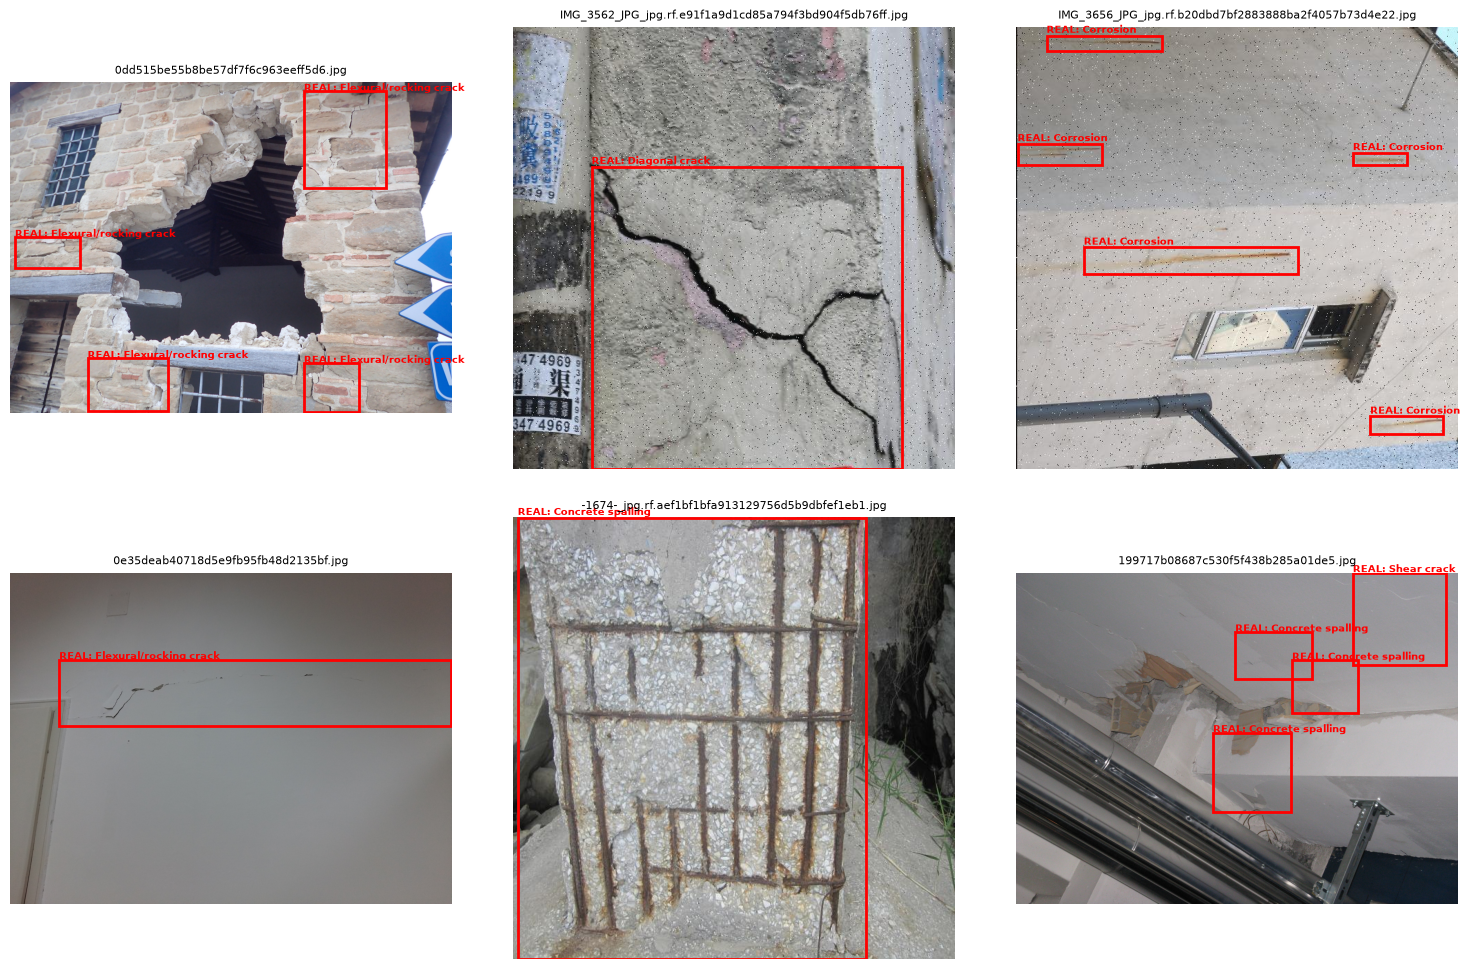

In [ ]:
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

def plot_predictions_vs_real(image_path, ax, umbral_obj=0.3):
    """Dibuja en ROJO las cajas reales y en VERDE las predicciones del modelo."""
    label_path = get_label_path(image_path)
    boxes_reales = parse_label_to_boxes(label_path)
    valid_reales = boxes_reales[:, 0] == 1

    img = Image.open(image_path)
    img_w, img_h = img.size
    ax.imshow(img)

    # --- Cajas reales (rojo) ---
    for xc, yc, w, h, *class_onehot in boxes_reales[valid_reales, 1:]:
        box_w, box_h = w * img_w, h * img_h
        x0, y0 = xc * img_w - box_w / 2, yc * img_h - box_h / 2
        rect = patches.Rectangle((x0, y0), box_w, box_h, linewidth=2,
                                  edgecolor="red", facecolor="none")
        ax.add_patch(rect)
        class_idx = int(np.argmax(class_onehot))
        ax.text(x0, y0 - 4, f"REAL: {CLASS_NAMES[class_idx]}",
                color="red", fontsize=7, weight="bold")

    # --- Predicción del modelo (verde) ---
    img_resized = tf.keras.utils.load_img(image_path, target_size=IMG_SIZE)
    img_array = tf.keras.utils.img_to_array(img_resized) / 255.0
    pred = modelo_deteccion.predict(img_array[None, ...], verbose=0)[0]

    obj_scores = tf.sigmoid(pred[:, 0]).numpy()
    box_preds = pred[:, 1:5]
    class_preds = tf.nn.softmax(pred[:, 5:], axis=-1).numpy()

    for slot in np.where(obj_scores > umbral_obj)[0]:
        xc, yc, w, h = box_preds[slot]
        box_w, box_h = w * img_w, h * img_h
        x0, y0 = xc * img_w - box_w / 2, yc * img_h - box_h / 2
        rect = patches.Rectangle((x0, y0), box_w, box_h, linewidth=2,
                                  edgecolor="lime", facecolor="none")
        ax.add_patch(rect)
        class_idx = int(np.argmax(class_preds[slot]))
        conf = obj_scores[slot]
        ax.text(x0, y0 + box_h + 10, f"PRED: {CLASS_NAMES[class_idx]} ({conf:.2f})",
                color="lime", fontsize=7, weight="bold")

    ax.set_title(os.path.basename(image_path), fontsize=8)
    ax.axis("off")


# Elegimos imágenes al azar de VALIDATION (no vistas en train)
muestras = random.sample(val_paths, 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, img_path in zip(axes.flat, muestras):
    plot_predictions_vs_real(img_path, ax)

plt.tight_layout()
plt.show()